# EWELD C24 — Modelli pre-addestrati su 2019 e 2020, con e senza meteo
Confronto dedicato ai soli modelli *foundation* usati **zero-shot** (nessun addestramento né tuning sui dati EWELD):

| Modello | Sviluppatore | Licenza pesi | Esecuzione |
|---|---|---|---|
| `TimesFM3_zeroshot` | Google | non commerciale (ricerca consentita) | MLX, GPU Apple |
| `TimesFM25_zeroshot` | Google | Apache 2.0 | PyTorch, CPU |
| `Chronos2_zeroshot` | Amazon | Apache 2.0 | PyTorch, GPU Apple (MPS) |
| `ChronosBolt_zeroshot` | Amazon | Apache 2.0 | PyTorch, GPU Apple (MPS) |

Il riferimento è il **naive giornaliero (`Naive24`)**, la baseline più forte emersa nella valutazione robusta.

**Due anni di test indipendenti.** Il protocollo è identico a `EWELD_C24_valutazione_robusta.ipynb` (profilo
`completo`): stesse utenze ammesse per anno (criterio di sola disponibilità dei dati), origini a 48 ore non
sovrapposte su tutto l'anno, stessa scala del MASE (refit ogni 28 giorni). Il 2019 fa da **replica**: i modelli
pre-addestrati non hanno parametri da scegliere, quindi la classifica del 2019 non è influenzata da quanto visto
nel 2020.

**Meteo.** Chronos-2 è l'unico dei quattro che accetta variabili esterne in modo nativo, quindi si provano due
varianti con i dati `Weather Data` di EWELD (stazione della zona dell'utenza):
- **`Chronos2_meteo`**: solo il meteo **passato** fino all'origine. È lo scenario realistico, senza informazioni future.
- **`Chronos2_meteo_oracolo`**: anche il meteo **osservato** nelle 48 ore future, come se la previsione meteo fosse
  perfetta. È un **limite superiore**: EWELD non contiene previsioni meteo archiviate, e in esercizio si userebbero
  previsioni con errore. Se nemmeno l'oracolo migliora, il meteo non serve a queste utenze.

TimesFM 2.5 supporterebbe covariate solo tramite una regressione lineare esterna (richiede JAX), Chronos-Bolt e
TimesFM 3.0 non le supportano: restano in versione solo-consumo.

## 1. Configurazione
I worker girano in venv separati (`.venv_timesfm`, `.venv_chronos`) tramite `eweld_timesfm.py` ed
`eweld_chronos.py`. Le previsioni già calcolate nella valutazione robusta (stesso protocollo, stesso contesto)
vengono riutilizzate dopo aver verificato che coprano esattamente le stesse coppie utente/origine.

In [1]:
from pathlib import Path
import sys, json, pickle, importlib, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import spearmanr

ROOT = next(p for p in (Path.cwd()/'datasets', Path.cwd()) if (p/'EWELD').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import eweld_multiutente as bench
import eweld_robusta as rob
import eweld_timesfm as tfm
import eweld_chronos as chronos_w
bench, rob, tfm, chronos_w = map(importlib.reload, (bench, rob, tfm, chronos_w))

YEARS = [2019, 2020]
REFERENCE = 'Naive24'
CONTEXT = 2048            # ore di contesto (circa 12 settimane), come nella valutazione robusta
ANOMALY = {2019: ('2019-01-25', '2019-02-25'),   # Capodanno lunare 2019
           2020: ('2020-01-10', '2020-03-31')}   # Capodanno lunare 2020 + lockdown COVID
# Stessi parametri del profilo `completo`: determinano utenze, origini e scala del MASE.
CFG = dict(horizon=48, lookback=168, train_days=365, origin_step=48, refit_days=28,
           min_train_coverage=.95, min_origin_coverage=.90, max_train_zero_share=.50,
           max_origins=None, max_refits=None)
PYTHON = {'timesfm': ROOT.parent/'.venv_timesfm'/'bin'/'python', 'chronos': ROOT.parent/'.venv_chronos'/'bin'/'python'}
ZERO_SHOT = ['timesfm3', 'timesfm25', 'chronos2', 'chronosbolt']
WEATHER_MODELS = ['chronos2_meteo', 'chronos2_meteo_oracolo']
LABEL = {'timesfm3': 'TimesFM3_zeroshot', 'timesfm25': 'TimesFM25_zeroshot', **chronos_w.LABELS}
FM = [LABEL[m] for m in ZERO_SHOT]
OUT = ROOT/'risultati_modelli_preaddestrati'
OUT.mkdir(exist_ok=True)
OLD = ROOT/'risultati_valutazione_robusta'   # cache della valutazione robusta (profilo completo)
for k, p in PYTHON.items():
    assert p.exists(), f'Manca il venv {p.parent.parent.name}: vedi le istruzioni nella valutazione robusta.'
print('Anni:', YEARS, '| contesto', CONTEXT, 'ore | riferimento', REFERENCE)

Anni: [2019, 2020] | contesto 2048 ore | riferimento Naive24


## 2. Dati meteo
`Weather Data/W1..W3.csv` contiene misure ogni 15 minuti per tre stazioni anonime; `User Location` associa ogni
utenza alla sua zona (CT1→W1, CT2→W2, CT3→W3). Tutte le acciaierie C24 sono in CT2 tranne U137 (CT1).

Variabili usate, in medie orarie: temperatura e punto di rugiada (°C), umidità relativa (%), velocità del vento
(m/s), pressione (hPa). Si escludono le raffiche (quasi sempre zero), la direzione del vento e `Condition` (assente
in W2).

**Causalità.** Nella variante realistica il valore dell'ora *t* è la media dell'ora *t−1* (ritardo di un'ora, come
nel notebook dei modelli con meteo): i dati a 15 minuti sono interpolati dal dataset, e il ritardo evita di usare
interpolazioni verso misure non ancora disponibili. La variante oracolo usa invece i valori osservati senza
ritardo, anche nelle 48 ore future.

In [2]:
panel = bench.load_panel(ROOT)
zone = bench.locations(ROOT, panel)
COLUMNS = {'Temperature(F)': 'temperatura', 'Dew Point(F)': 'punto_rugiada', 'Humidity(%)': 'umidita',
           'Wind Speed(mph)': 'vento', 'Pressure(in)': 'pressione'}

def load_weather(k):
    w = pd.read_csv(ROOT/f'EWELD/Weather Data/W{k}.csv', usecols=['Time', *COLUMNS], parse_dates=['Time'])
    w = w.set_index('Time').rename(columns=COLUMNS).sort_index()
    w['temperatura'] = (w.temperatura-32)*5/9
    w['punto_rugiada'] = (w.punto_rugiada-32)*5/9
    w['vento'] *= 0.44704          # mph → m/s
    w['pressione'] *= 33.8639      # inHg → hPa
    return w.resample('h').mean().asfreq('h')

WEATHER = {k: load_weather(k) for k in sorted(set(zone[u] for u in panel))}
WEATHER_PAST = {u: WEATHER[zone[u]].shift(1, freq='h') for u in panel}   # ritardo di un'ora
WEATHER_ORACLE = {u: WEATHER[zone[u]] for u in panel}                    # osservato, anche nel futuro
for k, w in WEATHER.items():
    print(f'W{k}: {w.index[0]:%d/%m/%Y} → {w.index[-1]:%d/%m/%Y}, ore mancanti {w.isna().any(axis=1).mean():.2%}')
display(WEATHER[2].loc['2019-01-01':'2020-12-31'].describe().T.round(1))

W1: 01/01/2015 → 01/11/2022, ore mancanti 0.00%
W2: 01/01/2015 → 01/11/2022, ore mancanti 0.00%


,count,mean,std,min,25%,50%,75%,max
temperatura,17544.0,23.8,5.1,6.5,20.0,24.6,27.8,36.0
punto_rugiada,17544.0,19.4,5.9,-7.7,15.8,20.2,24.6,28.7
umidita,17544.0,77.9,13.9,21.5,69.1,80.1,88.5,101.7
vento,17544.0,3.5,1.7,0.0,2.2,3.4,4.5,12.4
pressione,17544.0,1008.9,11.1,977.9,1000.7,1008.8,1016.9,1040.6


### 2.1 Il consumo dipende dal meteo?
Prima di aspettarsi un guadagno conviene guardare la relazione grezza: correlazione tra consumo giornaliero e
temperatura media giornaliera per utenza, nel 2019 e nel 2020. Un'acciaieria consuma soprattutto per il processo
produttivo, quindi ci si attende una dipendenza debole, salvo raffrescamento o riscaldamento degli ambienti.

In [3]:
corr = {}
for year in YEARS:
    for u in panel:
        period = slice(f'{year}-01-01', f'{year}-12-31 23:00')
        daily = panel[u].loc[period].resample('D').sum(min_count=20)
        temp = WEATHER[zone[u]].temperatura.loc[period].resample('D').mean()
        both = pd.concat([daily, temp], axis=1).dropna()
        if len(both) > 200 and both.iloc[:, 0].std() > 0:
            corr[(u, year)] = both.corr(method='spearman').iloc[0, 1]
CORR = pd.Series(corr).unstack()
display(CORR.style.format('{:+.2f}', na_rep='').background_gradient(cmap='RdBu', vmin=-1, vmax=1)
        .set_caption('Correlazione di Spearman tra consumo giornaliero e temperatura media giornaliera'))
print('Mediana |ρ|:', {y: round(float(CORR[y].abs().median()), 2) for y in CORR})

,2019,2020
U134,-0.21,+0.52
U135,+0.65,+0.55
U136,-0.08,+0.02
U137,+0.20,-0.12
U138,+0.30,
U141,+0.23,+0.29
U142,+0.47,+0.67
U143,-0.00,+0.38
U144,+0.20,+0.07
U147,-0.13,+0.27


Mediana |ρ|: {2019: 0.21, 2020: 0.33}


## 3. Utenze, origini e previsioni per anno
Per ogni anno si ricostruisce il protocollo della valutazione robusta e si eseguono i modelli. Ogni insieme di
previsioni viene salvato in `risultati_modelli_preaddestrati/<anno>/<modello>_ctx2048.pkl`; rieseguendo il notebook
le previsioni non vengono ricalcolate.

In [4]:
def setup(year):
    cfg = dict(CFG, test_start=f'{year}-01-01', test_end=f'{year}-12-31')
    audit = rob.eligibility(panel, cfg)
    users = sorted(audit.loc[audit.eligible, 'user'])
    origins = rob.test_origins(cfg)
    refits = rob.refit_dates(cfg, origins)
    return dict(year=year, cfg=cfg, audit=audit, users=users, origins=origins, refits=refits,
                refit_of=rob.assign_refit(origins, refits),
                origins_by_user={u: [o for o in origins if rob.window_ok(panel[u], o, cfg)] for u in users},
                out=OUT/str(year))

def forecasts(S, name):
    S['out'].mkdir(exist_ok=True)
    cache = S['out']/f'{name}_ctx{CONTEXT}.pkl'
    expected = {(u, o) for u, os in S['origins_by_user'].items() for o in os}
    for path in (cache, OLD/f"completo_{S['year']}"/f'{name}_ctx{CONTEXT}.pkl'):
        if path.exists():
            rows = pickle.loads(path.read_bytes())
            if {(r['user'], pd.Timestamp(r['origin'])) for r in rows} == expected:
                if path != cache:
                    cache.write_bytes(path.read_bytes())
                return rows, 'cache'
            print(f'{path} copre coppie diverse: ricalcolo.')
    t = time.perf_counter()
    if name.startswith('timesfm'):
        rows = tfm.run_from_notebook(name, panel, S['origins_by_user'], S['cfg'], PYTHON['timesfm'], CONTEXT)
    else:
        cov = {'chronos2_meteo': WEATHER_PAST, 'chronos2_meteo_oracolo': WEATHER_ORACLE}.get(name)
        rows = chronos_w.run_from_notebook(name, panel, S['origins_by_user'], S['cfg'], PYTHON['chronos'],
                                           CONTEXT, covariates=cov)
    cache.write_bytes(pickle.dumps(rows))
    return rows, f'{time.perf_counter()-t:.0f}s'

RUNS = {}
for year in YEARS:
    S = setup(year)
    S['rows'] = [r for r in rob.baseline_forecasts(panel, S['origins_by_user'], S['cfg']) if r['model'] == REFERENCE]
    log = {}
    for name in ZERO_SHOT+WEATHER_MODELS:
        rows, log[LABEL[name]] = forecasts(S, name)
        S['rows'] += rows
    RUNS[year] = S
    print(f"{year}: {len(S['users'])} utenze, {len(S['origins'])} origini, "
          f"{sum(map(len, S['origins_by_user'].values()))} coppie utente/origine | {log}")
both = sorted(set(RUNS[2019]['users']) & set(RUNS[2020]['users']))
print('Utenze in entrambi gli anni:', len(both), both)

2019: 16 utenze, 182 origini, 2912 coppie utente/origine | {'TimesFM3_zeroshot': 'cache', 'TimesFM25_zeroshot': 'cache', 'Chronos2_zeroshot': 'cache', 'ChronosBolt_zeroshot': 'cache', 'Chronos2_meteo': 'cache', 'Chronos2_meteo_oracolo': 'cache'}


2020: 11 utenze, 183 origini, 2013 coppie utente/origine | {'TimesFM3_zeroshot': 'cache', 'TimesFM25_zeroshot': 'cache', 'Chronos2_zeroshot': 'cache', 'ChronosBolt_zeroshot': 'cache', 'Chronos2_meteo': 'cache', 'Chronos2_meteo_oracolo': 'cache'}
Utenze in entrambi gli anni: 11 ['U135', 'U136', 'U137', 'U141', 'U142', 'U143', 'U144', 'U147', 'U148', 'U151', 'U155']


## 4. Risultati per anno
Per ciascun anno:
- **Classifica**: MASE medio/mediano sulle utenze, relMAE geometrica rispetto a `Naive24` e quota di utenze migliorate.
- **Bootstrap a blocchi** (7 origini = 14 giorni) per l'IC 95% della relMAE.
- **Diebold-Mariano per utente** contro `Naive24` (Holm sugli utenti).
- **Valutazione probabilistica**: copertura dell'intervallo 10–90% (nominale 80%) e pinball loss scalata.
- **Sensibilità** senza la finestra anomala dell'anno.

In [5]:
def prob_table(S):
    levels = np.arange(1, 10)/10
    out = []
    for r in S['rows']:
        if 'quantiles' in r:
            q, y = np.maximum(r['quantiles'], 0), np.asarray(r['actual'])
            loss = np.mean(np.maximum(levels*(y[:, None]-q), (levels-1)*(y[:, None]-q)))
            out.append(dict(model=r['model'], user=r['user'],
                            copertura_10_90=float(np.mean((y >= q[:, 0]) & (y <= q[:, -1]))),
                            pinball_scalata=loss/S['scales'][(r['user'], S['refit_of'][pd.Timestamp(r['origin'])])]))
    return pd.DataFrame(out).groupby(['model', 'user']).mean().groupby('model').mean()

def analyse(S):
    S['scales'] = rob.scale_table(panel, S['users'], S['refits'], S['cfg'])
    S['SM'] = rob.seed_mean(rob.metrics(S['rows'], S['scales'], S['refit_of']))
    board, S['per_user'] = rob.leaderboard(S['SM'], REFERENCE)
    S['boot'] = rob.block_bootstrap_relmae(S['SM'], REFERENCE).set_index('model')
    dmu = rob.dm_per_user(S['SM'], REFERENCE)
    S['dm_counts'] = dmu.groupby('model').esito.value_counts().unstack(fill_value=0).reindex(
        columns=['meglio', 'n.s.', 'peggio'], fill_value=0)
    S['prob'] = prob_table(S)
    a0, a1 = map(pd.Timestamp, ANOMALY[S['year']])
    normal = S['SM'][(S['SM'].origin+pd.Timedelta(CFG['horizon'], unit='h') <= a0) | (S['SM'].origin > a1)]
    S['board_normal'], _ = rob.leaderboard(normal, REFERENCE)
    table = board[['MASE_medio', 'MASE_mediano', 'relMAE_geom']].join(S['boot'][['IC95_inf', 'IC95_sup']])
    table['utenti_meglio_rif'] = board.quota_utenti_meglio_rif
    table = table.join(S['dm_counts'].rename(columns=lambda c: f'DM_{c}'))
    table['relMAE_senza_anomalia'] = S['board_normal'].relMAE_geom
    table = table.join(S['prob'])
    S['table'] = table.sort_values('relMAE_geom')
    S['out'].mkdir(exist_ok=True)
    S['table'].to_csv(S['out']/'classifica.csv')
    dmu.to_csv(S['out']/'dm_per_utente.csv', index=False)
    return S['table']

fmt = {c: '{:.3f}' for c in ['MASE_medio', 'MASE_mediano', 'relMAE_geom', 'IC95_inf', 'IC95_sup',
                             'relMAE_senza_anomalia', 'pinball_scalata']}
fmt.update(utenti_meglio_rif='{:.0%}', copertura_10_90='{:.1%}')
for year in YEARS:
    S = RUNS[year]
    display(Markdown(f"### {year} — {len(S['users'])} utenze, {len(S['origins'])} origini"))
    display(analyse(S).style.format(fmt, na_rep='—').set_caption(
        f"relMAE vs {REFERENCE}: < 1 = meglio. DM_* = utenze con differenza significativa (Holm 5%). "
        f"Senza anomalia: escluse {ANOMALY[year][0]} → {ANOMALY[year][1]}."))

### 2019 — 16 utenze, 182 origini

,MASE_medio,MASE_mediano,relMAE_geom,IC95_inf,IC95_sup,utenti_meglio_rif,DM_meglio,DM_n.s.,DM_peggio,relMAE_senza_anomalia,copertura_10_90,pinball_scalata
model,,,,,,,,,,,,
Chronos2_meteo,0.734,0.842,0.809,0.784,0.839,81%,13.000000,3.000000,0.000000,0.804,81.3%,0.297
TimesFM3_zeroshot,0.739,0.852,0.811,0.782,0.832,81%,13.000000,3.000000,0.000000,0.808,83.0%,0.299
Chronos2_zeroshot,0.738,0.835,0.815,0.787,0.847,81%,12.000000,4.000000,0.000000,0.810,79.5%,0.298
Chronos2_meteo_oracolo,0.757,0.862,0.832,0.809,0.862,81%,12.000000,4.000000,0.000000,0.829,79.7%,0.306
TimesFM25_zeroshot,0.763,0.870,0.839,0.801,0.871,81%,12.000000,4.000000,0.000000,0.830,83.8%,0.308
ChronosBolt_zeroshot,0.767,0.870,0.842,0.804,0.865,81%,12.000000,4.000000,0.000000,0.838,82.5%,0.311
Naive24,0.914,1.032,1.000,—,—,0%,—,—,—,1.000,—,—


### 2020 — 11 utenze, 183 origini

,MASE_medio,MASE_mediano,relMAE_geom,IC95_inf,IC95_sup,utenti_meglio_rif,DM_meglio,DM_n.s.,DM_peggio,relMAE_senza_anomalia,copertura_10_90,pinball_scalata
model,,,,,,,,,,,,
Chronos2_zeroshot,0.944,0.794,0.813,0.783,0.850,100%,10.000000,1.000000,0.000000,0.806,75.9%,0.381
Chronos2_meteo,0.946,0.779,0.815,0.790,0.848,100%,9.000000,2.000000,0.000000,0.810,78.0%,0.382
ChronosBolt_zeroshot,0.971,0.807,0.833,0.800,0.871,100%,9.000000,2.000000,0.000000,0.829,82.3%,0.392
TimesFM3_zeroshot,0.989,0.784,0.840,0.812,0.872,91%,10.000000,1.000000,0.000000,0.832,80.7%,0.399
Chronos2_meteo_oracolo,0.981,0.820,0.848,0.817,0.885,100%,7.000000,4.000000,0.000000,0.843,79.2%,0.398
TimesFM25_zeroshot,1.007,0.842,0.864,0.826,0.904,91%,7.000000,4.000000,0.000000,0.849,83.5%,0.408
Naive24,1.145,1.044,1.000,—,—,0%,—,—,—,1.000,—,—


### 4.1 Test sul pannello e ranghi
Diebold-Mariano sul MASE medio per origine per tutte le coppie (Holm su tutte le coppie dell'anno) e diagramma
delle differenze critiche di Nemenyi sui ranghi per utente: le barre blu uniscono modelli non distinguibili al 5%.
Con poche utenze il Nemenyi è conservativo; il DM sul pannello sfrutta invece tutte le ~180 origini.

**2019** — p-value di Holm, DM sul pannello (verde = differenza significativa)

,Chronos2_meteo,TimesFM3_zeroshot,Chronos2_zeroshot,Chronos2_meteo_oracolo,TimesFM25_zeroshot,ChronosBolt_zeroshot,Naive24
Chronos2_meteo,,1.000,1.000,0.000,0.100,0.195,0.000
TimesFM3_zeroshot,1.000,,1.000,0.126,0.013,0.126,0.000
Chronos2_zeroshot,1.000,1.000,,0.018,0.194,0.291,0.000
Chronos2_meteo_oracolo,0.000,0.126,0.018,,1.000,1.000,0.000
TimesFM25_zeroshot,0.100,0.013,0.194,1.000,,1.000,0.000
ChronosBolt_zeroshot,0.195,0.126,0.291,1.000,1.000,,0.000
Naive24,0.000,0.000,0.000,0.000,0.000,0.000,


**2020** — p-value di Holm, DM sul pannello (verde = differenza significativa)

,Chronos2_zeroshot,Chronos2_meteo,ChronosBolt_zeroshot,TimesFM3_zeroshot,Chronos2_meteo_oracolo,TimesFM25_zeroshot,Naive24
Chronos2_zeroshot,,1.000,0.036,0.225,0.018,0.006,0.000
Chronos2_meteo,1.000,,0.116,0.197,0.000,0.011,0.000
ChronosBolt_zeroshot,0.036,0.116,,1.000,1.000,0.225,0.000
TimesFM3_zeroshot,0.225,0.197,1.000,,1.000,0.876,0.000
Chronos2_meteo_oracolo,0.018,0.000,1.000,1.000,,0.854,0.000
TimesFM25_zeroshot,0.006,0.011,0.225,0.876,0.854,,0.001
Naive24,0.000,0.000,0.000,0.000,0.000,0.001,


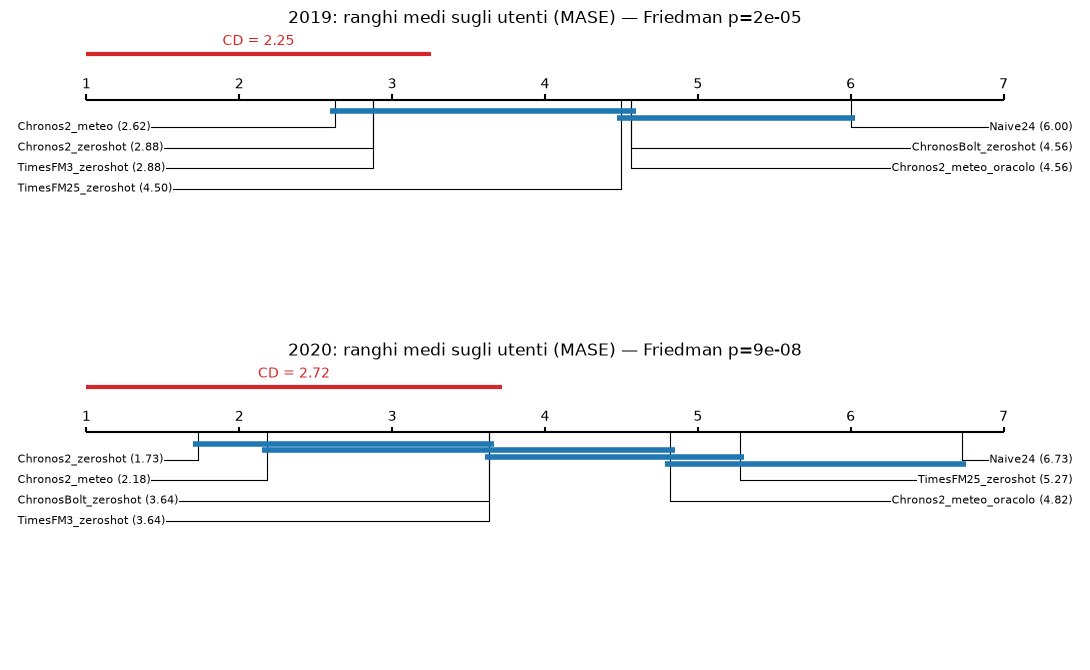

In [6]:
fig, axes = plt.subplots(len(YEARS), 1, figsize=(11, 3.4*len(YEARS)))
for ax, year in zip(np.atleast_1d(axes), YEARS):
    S = RUNS[year]
    dmp, _ = rob.dm_panel(S['SM'])
    dmp.to_csv(S['out']/'dm_pannello.csv', index=False)
    order = list(S['table'].index)
    P = pd.DataFrame(np.nan, index=order, columns=order)
    for r in dmp.itertuples():
        P.loc[r.A, r.B] = P.loc[r.B, r.A] = r.p_holm
    display(Markdown(f'**{year}** — p-value di Holm, DM sul pannello (verde = differenza significativa)'))
    display(P.style.format('{:.3f}', na_rep='').background_gradient(cmap='RdYlGn_r', vmin=0, vmax=.1))
    S['fn'] = fn = rob.friedman_nemenyi(rob.matrix(S['SM']))
    rob.plot_cd(fn['avg_ranks'], fn['cd'], ax, f"{year}: ranghi medi sugli utenti (MASE) — Friedman p={fn['p_friedman']:.1g}")
fig.tight_layout(); plt.show()
fig.savefig(OUT/'diagrammi_cd.png', dpi=160, bbox_inches='tight')

## 5. Il meteo aiuta Chronos-2?
Confronto diretto delle due varianti con meteo contro **Chronos-2 senza meteo** (stesso modello, stesso contesto):
bootstrap della relMAE e Diebold-Mariano per utente con riferimento `Chronos2_zeroshot`. È il confronto che isola
l'effetto delle variabili meteo.
Si escludono le utenze con consumo sempre nullo nell'anno di test (nel 2019 U154 e U156): su di esse il rapporto
tra due modelli non dice nulla sulla qualità della previsione.

In [7]:
BASE = 'Chronos2_zeroshot'
METEO = [LABEL[m] for m in WEATHER_MODELS]
rows = []
for year in YEARS:
    sm = RUNS[year]['SM']
    # Solo utenze con consumo non nullo nel test (relMAE vs Naive24 definita): su un contatore sempre a zero
    # il rapporto tra due modelli misura solo quanto ciascuno resta vicino allo zero.
    rel = RUNS[year]['per_user'].relMAE.unstack('model')[REFERENCE]
    active = rel[rel.notna()].index
    sub = sm[sm.model.isin([BASE, *METEO]) & sm.user.isin(active)]
    if len(active) < len(RUNS[year]['users']):
        print(f"{year}: escluse dal confronto sul meteo le utenze a consumo nullo nel test:",
              sorted(set(RUNS[year]['users'])-set(active)))
    boot = rob.block_bootstrap_relmae(sub, BASE).set_index('model')
    dmu = rob.dm_per_user(sub, BASE)
    counts = dmu.groupby('model').esito.value_counts().unstack(fill_value=0).reindex(columns=['meglio', 'n.s.', 'peggio'], fill_value=0)
    per = (dmu.pivot(index='user', columns='model', values='rel') < 1).mean()
    for m in METEO:
        rows.append(dict(anno=year, modello=m, relMAE_vs_Chronos2=boot.loc[m, 'relMAE_geom'],
                         IC95_inf=boot.loc[m, 'IC95_inf'], IC95_sup=boot.loc[m, 'IC95_sup'],
                         utenti_migliorati=per[m], **{f'DM_{k}': counts.loc[m, k] for k in counts.columns}))
    RUNS[year]['meteo_user'] = dmu.pivot(index='user', columns='model', values='rel')
METEO_EFFECT = pd.DataFrame(rows).set_index(['anno', 'modello'])
METEO_EFFECT.to_csv(OUT/'effetto_meteo.csv')
display(METEO_EFFECT.style.format({'relMAE_vs_Chronos2': '{:.3f}', 'IC95_inf': '{:.3f}', 'IC95_sup': '{:.3f}',
                                   'utenti_migliorati': '{:.0%}'})
        .set_caption('relMAE < 1: il meteo riduce l\'errore di Chronos-2. DM_* = utenze significative (Holm 5%).'))
per_user = pd.concat({y: RUNS[y]['meteo_user'] for y in YEARS}, axis=1)
display((1-per_user).style.format('{:+.3f}', na_rep='').background_gradient(cmap='RdBu', vmin=-.1, vmax=.1)
        .set_caption('Skill del meteo per utenza: 1 − MAE(con meteo)/MAE(Chronos-2 senza meteo)'))

2019: escluse dal confronto sul meteo le utenze a consumo nullo nel test: ['U154', 'U156']


## 6. Confronto tra i due anni
Se i modelli pre-addestrati sono davvero migliori di `Naive24`, l'IC deve restare sotto 1 in **entrambi** gli anni;
se la classifica tra loro è stabile, i ranghi devono coincidere. Il 2019 è una replica pulita: nessuna scelta di
questo notebook dipende dai risultati del 2019.

Concordanza della classifica dei 4 modelli zero-shot tra 2019 e 2020: Spearman 0.00


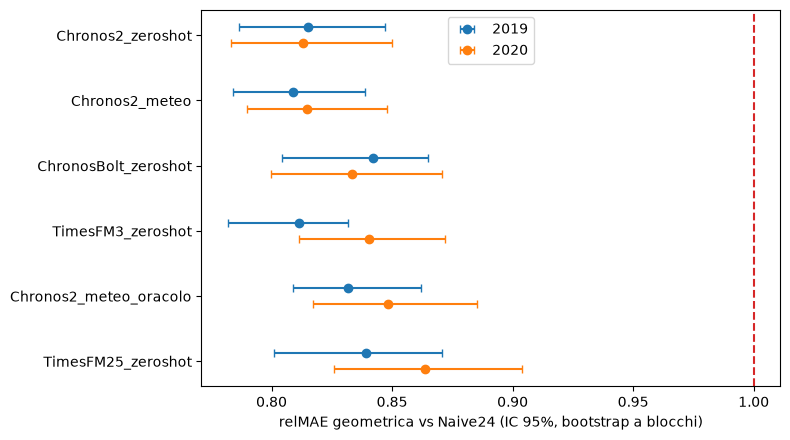

In [8]:
models = [m for m in RUNS[YEARS[-1]]['table'].index if m != REFERENCE]
CROSS = pd.concat({y: RUNS[y]['table'].loc[models, ['relMAE_geom', 'IC95_inf', 'IC95_sup', 'MASE_medio', 'pinball_scalata']]
                   for y in YEARS}, axis=1)
for y in YEARS:
    CROSS[(y, 'rango')] = CROSS[(y, 'relMAE_geom')].rank().astype(int)
CROSS = CROSS.sort_index(axis=1, level=0, sort_remaining=False)
CROSS.to_csv(OUT/'confronto_anni.csv')
display(CROSS.style.format('{:.3f}').format('{:d}', subset=[(y, 'rango') for y in YEARS]))
fm_rank = CROSS.loc[FM, [(y, 'relMAE_geom') for y in YEARS]]
rho, p = spearmanr(fm_rank.iloc[:, 0], fm_rank.iloc[:, 1])
print(f'Concordanza della classifica dei 4 modelli zero-shot tra {YEARS[0]} e {YEARS[1]}: Spearman {rho:.2f}')

fig, ax = plt.subplots(figsize=(8, .55*len(models)+1.2))
y = np.arange(len(models))
for k, (year, color) in enumerate(zip(YEARS, ['tab:blue', 'tab:orange'])):
    b = RUNS[year]['table'].loc[models]
    ax.errorbar(b.relMAE_geom, y+(k-.5)*.25, xerr=np.clip([b.relMAE_geom-b.IC95_inf, b.IC95_sup-b.relMAE_geom], 0, None),
                fmt='o', capsize=3, color=color, label=str(year))
ax.axvline(1, color='tab:red', ls='--'); ax.set_yticks(y, models); ax.invert_yaxis(); ax.legend()
ax.set_xlabel(f'relMAE geometrica vs {REFERENCE} (IC 95%, bootstrap a blocchi)'); fig.tight_layout(); plt.show()
fig.savefig(OUT/'confronto_anni.png', dpi=160, bbox_inches='tight')

## 7. Sintesi automatica
Frasi generate dai risultati, da verificare prima di usarle nella relazione. Limiti da dichiarare sempre:
non si può escludere che EWELD o serie simili siano nei corpus di pre-addestramento; la variante oracolo usa meteo
osservato al posto di previsioni; TimesFM 3.0 ha pesi a licenza non commerciale.

In [9]:
lines = []
for year in YEARS:
    S, t = RUNS[year], RUNS[year]['table']
    best = t.drop(REFERENCE).index[0]
    lines.append(f"{year} ({len(S['users'])} utenze, {len(S['origins'])} origini): migliore {best}, relMAE "
                 f"{t.loc[best, 'relMAE_geom']:.3f} [{t.loc[best, 'IC95_inf']:.3f}, {t.loc[best, 'IC95_sup']:.3f}] vs {REFERENCE}.")
    below = [m for m in FM if t.loc[m, 'IC95_sup'] < 1]
    lines.append(f"{year}: modelli zero-shot con IC tutto sotto 1: {len(below)}/{len(FM)} ({', '.join(below) or 'nessuno'}).")
    for m in METEO:
        e = METEO_EFFECT.loc[(year, m)]
        verdict = 'migliora' if e.IC95_sup < 1 else 'peggiora' if e.IC95_inf > 1 else 'non cambia in modo distinguibile'
        lines.append(f"{year}: {m} {verdict} Chronos-2 (relMAE {e.relMAE_vs_Chronos2:.3f} [{e.IC95_inf:.3f}, {e.IC95_sup:.3f}]).")
lines.append(f"Concordanza della classifica zero-shot tra gli anni: Spearman {rho:.2f}.")
print('\n'.join('- '+l for l in lines))
(OUT/'sintesi.md').write_text('\n'.join('- '+l for l in lines))

- 2019 (16 utenze, 182 origini): migliore Chronos2_meteo, relMAE 0.809 [0.784, 0.839] vs Naive24.
- 2019: modelli zero-shot con IC tutto sotto 1: 4/4 (TimesFM3_zeroshot, TimesFM25_zeroshot, Chronos2_zeroshot, ChronosBolt_zeroshot).
- 2019: Chronos2_meteo non cambia in modo distinguibile Chronos-2 (relMAE 0.992 [0.973, 1.006]).
- 2019: Chronos2_meteo_oracolo non cambia in modo distinguibile Chronos-2 (relMAE 1.020 [0.943, 1.040]).
- 2020 (11 utenze, 183 origini): migliore Chronos2_zeroshot, relMAE 0.813 [0.783, 0.850] vs Naive24.
- 2020: modelli zero-shot con IC tutto sotto 1: 4/4 (TimesFM3_zeroshot, TimesFM25_zeroshot, Chronos2_zeroshot, ChronosBolt_zeroshot).
- 2020: Chronos2_meteo non cambia in modo distinguibile Chronos-2 (relMAE 1.002 [0.989, 1.019]).
- 2020: Chronos2_meteo_oracolo peggiora Chronos-2 (relMAE 1.043 [1.021, 1.067]).
- Concordanza della classifica zero-shot tra gli anni: Spearman 0.00.


916